# 統制した自前のコーパスで小さな GPT を事前学習する (Trainer)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/08_transformers/gpt_from_scratch.ipynb)

NLP クックブック 08-12 ／ Transformers の基本操作

> GPU ランタイム推奨 (ランタイム → ランタイムのタイプを変更 → T4 GPU)

言語獲得や学習データの影響を調べる研究のために、自分で決めたコーパス (日本語版 Wikipedia の決まった約 2 万 2 千記事) だけで 1,400 万パラメータほどの GPT をゼロから事前学習し、学習途中のチェックポイントで、分野の違うテキストのパープレキシティと文法の最小対の正解率がどう変わるかを調べる。

In [1]:
!pip install -q datasets fugashi unidic-lite

In [2]:
import json, random
import numpy as np
import torch, transformers, datasets, tokenizers
from datasets import load_dataset

random.seed(0); np.random.seed(0); torch.manual_seed(0)
datasets.disable_progress_bars(); transformers.utils.logging.disable_progress_bar()   # 読み込みや加工の進捗バーを出さない
print("transformers", transformers.__version__, "/ datasets", datasets.__version__, "/ tokenizers", tokenizers.__version__, "/ torch", torch.__version__)

# 学習コーパス: 日本語版 Wikipedia (wikimedia/wikipedia の 20231101.ja。本文は CC BY-SA 3.0 と GFDL)。
# revision でデータセットの版 (コミット) を固定すると、あとで同じ記事を取り出し直せる
WIKI_REV = "b04c8d1ceb2f5cd4588862100d08de323dccfbaa"
wiki = load_dataset("wikimedia/wikipedia", "20231101.ja", split="train", streaming=True, revision=WIKI_REV)
# 25,000 記事を取り出して短い記事を除き、各記事の先頭 2,000 文字だけを使う (Colab で 1〜2 分)
arts = [a for a in wiki.shuffle(seed=0, buffer_size=10000).take(25000) if len(a["text"]) >= 300]
texts = [a["text"][:2000] for a in arts]
train_texts, val_texts = texts[:-500], texts[-500:]   # 最後の 500 記事は学習に使わず、検証用に取っておく
# 何を学習させたかを記録しておく (研究では、この一覧とコードがあればコーパスを再現できる)
json.dump({"dataset": "wikimedia/wikipedia", "config": "20231101.ja", "revision": WIKI_REV, "max_chars": 2000,
           "train_ids": [a["id"] for a in arts[:-500]], "val_ids": [a["id"] for a in arts[-500:]]},
          open("corpus_manifest.json", "w"))
print(len(train_texts), "記事 (学習) /", len(val_texts), "記事 (検証)", f"学習データ {sum(map(len, train_texts)) / 1e6:.1f}M 文字")

# 分野の違う評価用テキスト: 青空文庫の新字新仮名の作品 (globis-university/aozorabunko-clean、CC BY 4.0。
# 収録作品は著作権の切れたもの)。学習には一切使わない
aozora = load_dataset("globis-university/aozorabunko-clean", split="train", streaming=True,
                      revision="42a9c9c0f1d67e6a5554d9bea4201973dc9b049c")
works = [w for w in aozora.shuffle(seed=0, buffer_size=2000).take(1000) if w["meta"]["文字遣い種別"] == "新字新仮名"]
ood_texts = ["\n".join(p.strip() for p in w["text"].split("\n") if len(p.strip()) >= 20)[:2000] for w in works]
ood_texts = [t for t in ood_texts if len(t) >= 300][:300]
print(len(ood_texts), "作品 (青空文庫、評価用)")

transformers 5.22.1 / datasets 4.8.5 / tokenizers 0.23.3 / torch 2.14.1+cu130
21937 記事 (学習) / 500 記事 (検証) 学習データ 29.2M 文字
300 作品 (青空文庫、評価用)


In [3]:
from tokenizers import Tokenizer, decoders, models, normalizers, pre_tokenizers, trainers
from transformers import PreTrainedTokenizerFast

# トークナイザーも同じコーパスから作る (既存のトークナイザーを使うと、その学習データの影響が入る)。
# GPT-2 と同じバイト単位の BPE で、未知語 ([UNK]) が出ない
bpe = Tokenizer(models.BPE())
bpe.normalizer = normalizers.NFKC()
bpe.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe.decoder = decoders.ByteLevel()
trainer_tok = trainers.BpeTrainer(vocab_size=8000, special_tokens=["<|endoftext|>", "<|pad|>"],
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
bpe.train_from_iterator(train_texts[:8000], trainer_tok)        # 語彙は学習用の記事の一部 8,000 記事から作る (1 分以内)
# パディング用のトークンは <|endoftext|> と別にする (注意書きを参照)
tokenizer = PreTrainedTokenizerFast(tokenizer_object=bpe, bos_token="<|endoftext|>", eos_token="<|endoftext|>", pad_token="<|pad|>")
tokenizer.save_pretrained("gpt-ja-tokenizer")
ids = tokenizer("吾輩は猫である。自然言語処理は人工知能の一分野である。")["input_ids"]
print(len(ids), "トークン:", [tokenizer.decode([i]) for i in ids])

18 トークン: ['吾', '輩', 'は', '猫', 'である', '。', '自然', '言語', '処理', 'は', '人', '工', '知', '能', 'の一', '分野', 'である', '。']


In [4]:
import itertools
from datasets import Dataset

BLOCK = 256
def tokenize(batch):
    # 記事の終わりに <|endoftext|> を付ける
    return {"input_ids": [x + [tokenizer.eos_token_id] for x in tokenizer(batch["text"])["input_ids"]]}

def group(batch):
    # 記事をつなげて 256 トークンずつのブロックに切る (端数は捨てる。Hugging Face の run_clm.py と同じ方法)
    ids = list(itertools.chain.from_iterable(batch["input_ids"]))
    n = len(ids) // BLOCK * BLOCK
    return {"input_ids": [ids[i:i + BLOCK] for i in range(0, n, BLOCK)]}

def to_blocks(texts):
    ds = Dataset.from_dict({"text": texts}).map(tokenize, batched=True, remove_columns=["text"])
    n_tok = sum(map(len, ds["input_ids"]))
    return ds.map(group, batched=True, batch_size=1000), n_tok / sum(map(len, texts))   # (ブロック, 1 文字あたりのトークン数)

train_ds, _ = to_blocks(train_texts)                 # Colab で 1 分ほど (2 コアに制限して 38 秒)
eval_ds, tok_per_char = {}, {}
eval_ds["wiki"], tok_per_char["wiki"] = to_blocks(val_texts)
eval_ds["aozora"], tok_per_char["aozora"] = to_blocks(ood_texts)
print(f"学習 {len(train_ds)} ブロック ({len(train_ds) * BLOCK / 1e6:.1f}M トークン)  評価", {k: len(v) for k, v in eval_ds.items()}, "ブロック")
print("1 トークンあたりの文字数", {k: round(1 / v, 2) for k, v in tok_per_char.items()})

# 比較の基準: 文脈を見ずに出現頻度だけで予測するモデル (ユニグラム) の損失
counts = np.bincount(np.array(train_ds["input_ids"]).ravel(), minlength=len(tokenizer)) + 1.0
unigram_logp = np.log(counts / counts.sum())
unigram_loss = {k: float(-unigram_logp[np.array(v["input_ids"])].mean()) for k, v in eval_ds.items()}
print("ユニグラムの損失", {k: round(v, 3) for k, v in unigram_loss.items()})

学習 73289 ブロック (18.8M トークン)  評価 {'wiki': 1710, 'aozora': 1630} ブロック
1 トークンあたりの文字数 {'wiki': 1.55, 'aozora': 1.35}
ユニグラムの損失 {'wiki': 7.519, 'aozora': 7.67}


In [5]:
import math, time
from transformers import (DataCollatorForLanguageModeling, GPT2Config, GPT2LMHeadModel,
                          Trainer, TrainerCallback, TrainingArguments)

BF16 = torch.cuda.get_device_capability()[0] >= 8    # bfloat16 は Ampere (A100, L4) 以降。T4 では float16 を使う
config = GPT2Config(vocab_size=len(tokenizer), n_positions=BLOCK, n_embd=384, n_layer=6, n_head=6,
                    resid_pdrop=0.0, embd_pdrop=0.0, attn_pdrop=0.0,            # データを 2 周ほどしか見ないのでドロップアウトなし
                    bos_token_id=tokenizer.bos_token_id, eos_token_id=tokenizer.eos_token_id,
                    pad_token_id=tokenizer.pad_token_id)
torch.manual_seed(0)
model = GPT2LMHeadModel(config)                       # from_pretrained ではなく、設定から重みがランダムなモデルを作る
print(f"{model.num_parameters() / 1e6:.1f}M パラメータ")

# 学習の途中経過を調べるステップ (言語獲得の研究では、学習の初期に細かく取る)。このステップで評価し、チェックポイントを保存する
SAVE_AT = [50, 100, 200, 500, 1000, 2000, 3500, 5000]
class EvalAndSaveAt(TrainerCallback):
    def on_step_end(self, args, state, control, **kwargs):
        if state.global_step in SAVE_AT:
            control.should_evaluate = control.should_save = True
        return control

args = TrainingArguments(
    output_dir="gpt-ckpt", max_steps=5000, per_device_train_batch_size=32, per_device_eval_batch_size=64,
    learning_rate=1e-3, warmup_steps=200, lr_scheduler_type="cosine_with_min_lr", lr_scheduler_kwargs={"min_lr_rate": 0.1},
    weight_decay=0.1, adam_beta2=0.95, max_grad_norm=1.0, bf16=BF16, fp16=not BF16,
    logging_steps=250, eval_strategy="no", save_strategy="no", save_only_model=True,   # 評価と保存は上のコールバックで決める
    report_to="none", seed=0, data_seed=0)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,   # 評価用を辞書で渡すと eval_wiki_loss のように別々に記録される
                  data_collator=DataCollatorForLanguageModeling(tokenizer, mlm=False),       # labels = input_ids (1 つずらすのはモデルの中で行う)
                  callbacks=[EvalAndSaveAt()])

log = {0: trainer.evaluate()}                        # 学習前 (重みがランダム) の損失
# 健全性の確認: 学習前のモデルはほぼ一様な予測をするので、損失は log (語彙の大きさ) に近いはず
print(f"学習前の損失 {log[0]['eval_wiki_loss']:.3f}  log {len(tokenizer)} = {math.log(len(tokenizer)):.3f}")
trainer.save_model("gpt-ckpt/checkpoint-0")
t0 = time.time()
trainer.train()                                      # T4 で 15〜20 分 (A5000 で 5 分弱から見積もり。最初に出る loss_type=None の警告は無害)
seen = trainer.state.global_step * args.per_device_train_batch_size * BLOCK
print(f"学習 {time.time() - t0:.0f} 秒、{trainer.state.epoch:.1f} エポック (延べ {seen / 1e6:.1f}M トークン、パラメータ数の {seen / model.num_parameters():.1f} 倍)、"
      f"GPU メモリの最大使用量 {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
for h in trainer.state.log_history:               # 評価の結果は評価用のデータごとに別の行で記録されるので、ステップでまとめる
    if any(k.startswith("eval_") for k in h):
        log.setdefault(h["step"], {}).update(h)
train_loss = {h["step"]: h["loss"] for h in trainer.state.log_history if "loss" in h}   # 直前 250 ステップの平均
for s, h in log.items():
    tr = f"{train_loss[s]:.3f}" if s in train_loss else "  -  "
    print(f"step {s:5}  学習 {tr}  検証 (Wikipedia) {h['eval_wiki_loss']:.3f}  青空文庫 {h['eval_aozora_loss']:.3f}")

13.8M パラメータ


Training Loss,Validation Loss,Step,Wiki Loss
No log,No log,0,9.007683


Training Loss,Validation Loss,Step,Aozora Loss
No log,No log,0,9.030515


学習前の損失 9.008  log 8000 = 8.987


Step,Training Loss,Validation Loss,Wiki Loss,Aozora Loss
50,No log,No log,7.413571,7.572308
100,No log,No log,6.872912,7.140507
200,No log,No log,6.184076,6.624318
250,6.866397,No Log,No Log,No Log
500,5.670172,No log,5.397125,6.103973
750,5.216217,No Log,No Log,No Log
1000,4.894059,No log,4.801701,5.750713
1250,4.688820,No Log,No Log,No Log
1500,4.538612,No Log,No Log,No Log
1750,4.378793,No Log,No Log,No Log


学習 285 秒、2.2 エポック (延べ 41.0M トークン、パラメータ数の 3.0 倍)、GPU メモリの最大使用量 2.6 GB
step     0  学習   -    検証 (Wikipedia) 9.008  青空文庫 9.031
step    50  学習   -    検証 (Wikipedia) 7.414  青空文庫 7.572
step   100  学習   -    検証 (Wikipedia) 6.873  青空文庫 7.141
step   200  学習   -    検証 (Wikipedia) 6.184  青空文庫 6.624
step   500  学習 5.670  検証 (Wikipedia) 5.397  青空文庫 6.104
step  1000  学習 4.894  検証 (Wikipedia) 4.802  青空文庫 5.751
step  2000  学習 4.238  検証 (Wikipedia) 4.205  青空文庫 5.388
step  3500  学習 3.758  検証 (Wikipedia) 3.817  青空文庫 5.121
step  5000  学習 3.499  検証 (Wikipedia) 3.681  青空文庫 5.036


In [6]:
import fugashi

# 文法の最小対を、学習に使っていない検証用の記事の文から自動で作る (各 300 組)
#   助詞: 格助詞「が・を・に」の 1 つを別のものに替える  語順: 隣り合う 2 つの形態素を入れ替える
tagger = fugashi.Tagger()
rng = random.Random(0)
# 「概要」などの見出しが文に混ざらないよう、段落 (行) に分け、「。」で終わる段落だけから文を取り出す
sents = [s.strip() + "。" for t in val_texts for para in t.split("\n") if para.strip().endswith("。")
         for s in para.strip().split("。") if 15 <= len(s.strip()) <= 60]
rng.shuffle(sents)
pairs = {"助詞": [], "語順": []}
for s in sents:
    w = [(m.surface, m.feature.pos1, m.feature.pos2) for m in tagger(s)]
    # pos2 で格助詞に絞る (「雨が降ったが、」の 2 つ目の「が」のような接続助詞は除く)
    cands = [i for i, (x, _, p2) in enumerate(w) if p2 == "格助詞" and x in ("が", "を", "に")]
    if cands and len(pairs["助詞"]) < 300:
        i = rng.choice(cands); new = rng.choice([x for x in ("が", "を", "に") if x != w[i][0]])
        pairs["助詞"].append((s, "".join(x if j != i else new for j, (x, *_) in enumerate(w))))
    cands = [i for i in range(len(w) - 2) if w[i][1] != "補助記号" and w[i + 1][1] != "補助記号" and w[i][0] != w[i + 1][0]]
    if cands and len(pairs["語順"]) < 300:
        i = rng.choice(cands); v = [x for x, *_ in w]; v[i], v[i + 1] = v[i + 1], v[i]
        pairs["語順"].append((s, "".join(v)))
for k, v in pairs.items():
    print(k, len(v), "組  例:", v[0][0], "/", v[0][1])

@torch.no_grad()
def logprob(model, texts, bs=100):
    """文頭に <|endoftext|> を置いたときの、文全体の対数尤度 (各トークンの対数確率の和)"""
    out = []
    for i in range(0, len(texts), bs):
        enc = tokenizer([tokenizer.bos_token + t for t in texts[i:i + bs]], return_tensors="pt", padding=True,
                        return_token_type_ids=False).to(model.device)
        lp = model(**enc).logits[:, :-1].float().log_softmax(-1)
        tgt = enc["input_ids"][:, 1:]
        out += (lp.gather(-1, tgt[..., None])[..., 0] * enc["attention_mask"][:, 1:]).sum(1).tolist()
    return np.array(out)

def score(lp_good, lp_bad):
    """組ごとの得点: 正しい文の対数尤度が高ければ 1、同点なら 0.5、低ければ 0"""
    tie = np.isclose(lp_good, lp_bad, rtol=0, atol=1e-6)
    return np.where(tie, 0.5, (lp_good > lp_bad).astype(float))

# 各チェックポイントで、正しい文の対数尤度が崩した文より高い組の割合を数える (Colab で 1 分ほど)
correct = {}
for s in [0] + SAVE_AT:
    ckpt = GPT2LMHeadModel.from_pretrained(f"gpt-ckpt/checkpoint-{s}").to("cuda").eval()
    correct[s] = {k: score(logprob(ckpt, [g for g, _ in v]), logprob(ckpt, [b for _, b in v])) for k, v in pairs.items()}

# 対照: 文脈を見ないユニグラムでも、トークン数や語の頻度の違いだけで正しい文を選べることがある。
# 語順を入れ替えてもトークンの集合が変わらない組は、ユニグラムでは同点になる (0.5 と数える)
def unigram_lp(texts):
    return np.array([unigram_logp[x].sum() for x in tokenizer(texts)["input_ids"]])
for k, v in pairs.items():
    g, b = unigram_lp([g for g, _ in v]), unigram_lp([b for _, b in v])
    print(f"ユニグラムでの最小対 ({k}) の正解率 {score(g, b).mean():.3f}  (同点 {np.isclose(g, b, rtol=0, atol=1e-6).sum()} 組)")

助詞 300 組  例: 1985年に本国デビューしているが、日本では1987年から導入。 / 1985年を本国デビューしているが、日本では1987年から導入。
語順 300 組  例: 1985年に本国デビューしているが、日本では1987年から導入。 / 1985年本国にデビューしているが、日本では1987年から導入。
ユニグラムでの最小対 (助詞) の正解率 0.640  (同点 0 組)
ユニグラムでの最小対 (語順) の正解率 0.635  (同点 87 組)


      PPL (wiki)  bit/文字 (wiki)  PPL (aozora)  bit/文字 (aozora)  最小対 (助詞)  最小対 (語順)
step                                                                              
0       8165.578          8.376      8354.158            9.683     0.687     0.633
50      1658.338          6.894      1943.620            8.120     0.657     0.633
100      965.757          6.391      1262.068            7.657     0.690     0.800
200      484.965          5.751       753.190            7.103     0.760     0.873
500      220.771          5.019       447.633            6.545     0.830     0.910
1000     121.717          4.465       314.415            6.166     0.850     0.940
2000      66.998          3.910       218.766            5.778     0.917     0.967
3500      45.478          3.550       167.445            5.491     0.920     0.980
5000      39.695          3.423       153.920            5.401     0.917     0.970
ユニグラム: bit/文字 {'wiki': 6.99, 'aozora': 8.22}
step   200 助詞 0.760 [0.713, 0.807]  語順 0.8

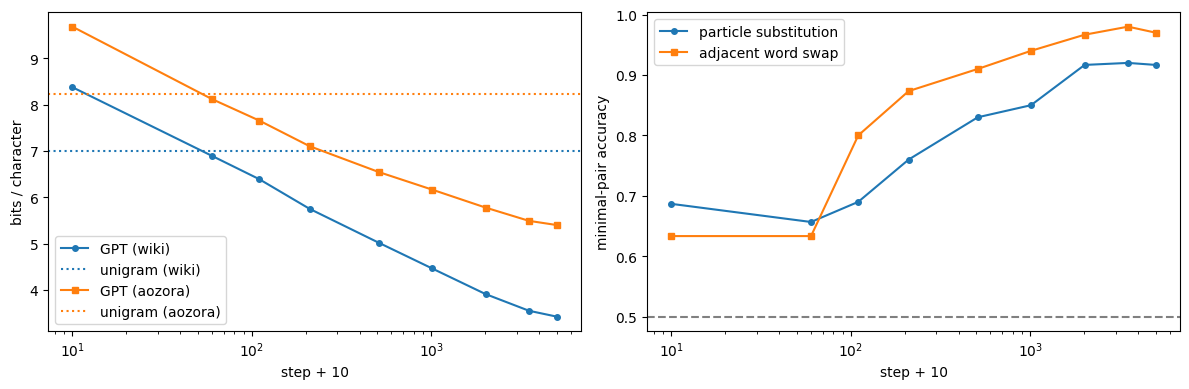

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# 損失 (1 トークンあたり、自然対数) をトークナイザーによらない 1 文字あたりのビット数にも直す
rows = []
for s in [0] + SAVE_AT:
    r = {"step": s}
    for k in ["wiki", "aozora"]:
        r[f"PPL ({k})"] = math.exp(log[s][f"eval_{k}_loss"])
        r[f"bit/文字 ({k})"] = log[s][f"eval_{k}_loss"] * tok_per_char[k] / math.log(2)
    r |= {f"最小対 ({k})": c.mean() for k, c in correct[s].items()}
    rows.append(r)
df = pd.DataFrame(rows).set_index("step")
print(df.round(3).to_string())
print("ユニグラム: bit/文字", {k: round(unigram_loss[k] * tok_per_char[k] / math.log(2), 2) for k in unigram_loss})

# 最小対の正解率の 95% 信頼区間 (組を単位にしたブートストラップ)。評価は各 300 組なので幅はおよそ ±0.04
brng = np.random.default_rng(0)
def ci(c, n=2000):
    boot = [c[brng.integers(0, len(c), len(c))].mean() for _ in range(n)]
    return np.percentile(boot, 2.5), np.percentile(boot, 97.5)
for s in [200, 1000, SAVE_AT[-1]]:
    print(f"step {s:5}", "  ".join(f"{k} {c.mean():.3f} [{lo:.3f}, {hi:.3f}]" for k, c in correct[s].items() for lo, hi in [ci(c)]))

x = np.array(df.index) + 10                           # 対数軸に 0 を置けないので 10 ずらす
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for k, m in [("wiki", "o-"), ("aozora", "s-")]:
    axes[0].plot(x, df[f"bit/文字 ({k})"], m, ms=4, label=f"GPT ({k})")
    axes[0].axhline(unigram_loss[k] * tok_per_char[k] / math.log(2), ls=":", color="C0" if k == "wiki" else "C1", label=f"unigram ({k})")
axes[0].set_xscale("log"); axes[0].set_xlabel("step + 10"); axes[0].set_ylabel("bits / character"); axes[0].legend()
axes[1].plot(x, df["最小対 (助詞)"], "o-", ms=4, label="particle substitution")
axes[1].plot(x, df["最小対 (語順)"], "s-", ms=4, label="adjacent word swap")
axes[1].axhline(0.5, color="gray", ls="--")
axes[1].set_xscale("log"); axes[1].set_xlabel("step + 10"); axes[1].set_ylabel("minimal-pair accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

In [8]:
from transformers import pipeline, set_seed

# チェックポイントごとの生成文 (同じ乱数の種で、temperature 0.8、top_p 0.95 のサンプリング)
for s in [0, 200, 1000, 5000]:
    gen = pipeline("text-generation", model=f"gpt-ckpt/checkpoint-{s}", tokenizer=tokenizer, device=0)
    print(f"--- step {s}")
    for prompt in ["日本の首都は", "私は"]:
        set_seed(0)
        out = gen(tokenizer.bos_token + prompt, max_new_tokens=40, do_sample=True, temperature=0.8, top_p=0.95, top_k=0)
        print("  ", out[0]["generated_text"].replace(tokenizer.bos_token, "").replace("\n", " "))

--- step 0
   日本の首都は紹方向取引伝説共和国カス学園綬w海外ルスかつて存在した行動高等学校一覧上の砲二郎はの�最初の緑布薦港区ent基本的にマスター者の指定としても1965有名にするーリングを退多かった Al返を与を卒業
   私は紹方向取引伝説共和国カス学園綬w海外ルスかつて存在した行動高等学校一覧上のこれにエピソードはの�最初の緑布富山港区アニメーション基本的に短編今えられと一1965有名名をファンを退多かった Al返を与チャンピオン
--- step 200
   日本の首都はいこ 土原前学園、新戸敷(これが筆(元川は 第昭和27年)が正田重今平和    大雄   189
   私はいこん替え 『学園、新海外、大沢地区(元川は 第昭和27年)  『重今平和  ひ
--- step 1000
   日本の首都はいでんしゃ♋、whophocha.sは、最初のメートゥーで、インディーザー・ガツ・ファン・キリリル・
   私はいぶんしゃ♋、whophocha.sは、最初のメートゥーで、短編小説。  初回盤  初タイトル- (漫画
--- step 5000
   日本の首都は、東京都千代田区にある。  概要  東京都港区の一般社団法人。東京都千代田区緑ケ丘。2006年2月26日に開始。  大学概要  大学全体
   私は言わずに妻を変えて、身を絞って痢に伝える。先祖ともいい、正当な者の方をよく持つ。  概要  世


- 公開されている事前学習済みモデルは学習データが膨大で、評価に使う文が学習データに入っていたかどうかも確かめにくい。言語獲得や学習データの影響を調べる研究では、ここのようにコーパスを自分で決めてゼロから学習する。データセットの `revision`、記事の一覧 (`corpus_manifest.json`)、トークナイザー、乱数の種、ライブラリの版を残しておけば、同じ条件で学習し直せる。学習データを操作する実験 (ある構文を含む文を除く、分野の比率を変えるなど) は、`train_texts` を差し替えて同じコードで比べる (ここでは試していない)。学習途中のチェックポイントを公開して同じ目的に使えるようにしたモデル群に Pythia (Biderman et al., 2023) がある。
- このコーパスの性質も記録しておく。各記事の先頭 2,000 文字だけを使うので、記事の冒頭 (「〜は、…である。」という定義の文や概要) に偏る。ストリーミングの `shuffle` は 10,000 件のバッファの中で混ぜるだけの近似で、Wikipedia 全体から一様に選んだ標本ではない。どちらも記事の一覧があれば後から確かめられるが、論文などでは「無作為に選んだ記事」とは書かない。
- 学習ループは Trainer に任せ、`DataCollatorForLanguageModeling(mlm=False)` が `labels` に `input_ids` の写しを入れる (1 つずらすのはモデルの中)。このコレーターはパディングのトークンと同じ ID のラベルを -100 (損失に入れない) にするので、よく見る `pad_token = eos_token` にすると、記事の区切りの `<|endoftext|>` もすべて学習されなくなる。ここでは `<|pad|>` を別に作った。評価と保存のステップはコールバックで指定し、`save_only_model=True` でチェックポイントをモデルの重みだけ (1 つ 54MB、9 つで約 480MB) にした。オプティマイザーの状態がないので、これらのチェックポイントから学習を再開することはできない。
- 5,000 ステップ (2.2 エポック) で、学習に使っていない Wikipedia の記事の PPL は 39.7、学習に一切使っていない青空文庫の作品は 153.9 だった。語彙が Wikipedia から作られているので青空文庫は 1 トークンあたりの文字数が少なく (1.35 文字。Wikipedia は 1.55 文字。語彙 8,000 では「吾輩」「人工知能」も 1 文字ずつに分かれる)、トークンあたりの PPL では比べられない。1 文字あたりのビット数にそろえると Wikipedia 3.42 bit、青空文庫 5.40 bit で、ユニグラム (6.99 bit、8.22 bit) からの下がり方は Wikipedia の方が大きい。学習データの分野の違いがそのまま評価に出る。
- 学習前の損失 9.008 は、語彙 8,000 の一様分布の log 8000 = 8.987 にほぼ等しい。大きく離れていれば、ラベルのずらし方や初期化を疑う。学習の損失 (直前 250 ステップの平均) は 2,000 ステップでは検証より 0.033 高かったが、3,500 ステップで 0.059、5,000 ステップで 0.182 低くなった。同じデータを 2 周以上したことによる過学習の始まりで、これ以上ステップを増やすならデータも増やす。学習したトークンは延べ 41.0M (重複しないのは 18.8M) で、パラメータ数 13.8M の約 3 倍しかない。Chinchilla (Hoffmann et al., 2022) は 70B パラメータを 1.4 兆トークン (約 20 倍) で学習しており、それに比べるとデータがかなり少ない。データ量をそろえて比べる研究では、この比も条件として書いておく。エンコーダー・デコーダーをゼロから学習する例は、機械翻訳の章の「Transformer の翻訳モデルをゼロから学習する」にある。
- 文法の最小対の正解率は、最後のチェックポイントで格助詞の置き換え 0.917 (95% 信頼区間 [0.883, 0.947])、隣り合う形態素の入れ替え 0.970 ([0.950, 0.987]) だった。ただし重みがランダムな学習前のモデルでも 0.687 と 0.633、文脈を見ないユニグラムでも 0.640 と 0.635 になる (語順の 300 組のうち 87 組はトークンの集合が同じでユニグラムでは区別できず、0.5 と数えた)。トークン数や語の頻度の違いだけで選べる組があるので、0.5 ではなく、このような対照と比べる。この 1 回の実行 (種は 1 つ、各 300 組) では、200 ステップで語順 0.873 ([0.837, 0.910]) に対して助詞 0.760 ([0.713, 0.807]) と、助詞の方が遅れて上がった。2 つの課題は対照の水準も違うので、獲得の順序として主張するには、種を変えた複数の実行と人手で確かめた最小対が要る。
- 最小対は検証用の記事の文から機械的に作ったもので、人手で確かめていない。「が」と「を」を入れ替えても文法的なままの組や、1 組の差が助詞以外の要因で決まる組も混ざりうる。系統的に調べるなら、この章の「言語モデルの文法知識を最小対で調べる (BLiMP / JBLiMP)」のような人手で作った最小対を使う。生成文は、学習前はでたらめなトークンの列、200 ステップと 1,000 ステップでは記号や断片が並ぶだけで、5,000 ステップで「日本の首都は、東京都千代田区にある。」のあとに「概要」のような Wikipedia の見出しが続く文章になった (各チェックポイントで 1 回ずつサンプリングしただけなので、傾向として見る程度にとどめる)。
- 13.8M パラメータで、GPU メモリの最大使用量は 2.6 GB。数値と生成文は、検証のマシン (RTX A5000、T4 と同じ float16 の経路) での 1 回の結果で、学習のセルは 297 秒 (うち `trainer.train()` は 285 秒) だった。T4 はこれより遅い。GPU が違うと計算の細部が変わり、生成文などは別のものになりうる。版をそろえるなら `!pip install -q transformers==5.22.1 datasets==4.8.5` のように固定する (検証は transformers 5.22.1、datasets 4.8.5、tokenizers 0.23.3、torch 2.14.1)。
- データは日本語版 Wikipedia (wikimedia/wikipedia の 20231101.ja、データセットカードによれば CC BY-SA 3.0 と GFDL) と青空文庫 (globis-university/aozorabunko-clean、CC BY 4.0)。ライブラリは transformers、datasets、tokenizers が Apache 2.0、fugashi が MIT と BSD 3 条項、unidic-lite がパッケージは MIT で、同梱の UniDic 2.1.2 の辞書は GPL、LGPL、BSD のいずれかを選べる (パッケージに同梱の COPYING による)。トークナイザーの学習は、サブワードとトークナイザの章の「Hugging Face tokenizers で BPE / WordPiece を学習する」を参照。仕組みを自分で実装して確かめる版は、付録「仕組みを理解するための実装」の「小さな GPT を日本語のテキストでゼロから事前学習する (学習ループを自分で書く)」にある。